# eSCALE × DES Y3: selection-modelled $L_X$–$M$ fits

This notebook continues `lx_mass_fits.ipynb` (deterministic fits) and `lx_selection_modelling.ipynb` (the selection model). It uses `scripts/lx/fit_escale_sel.py` and `scripts/lx/make_escale_mock.py`, on branch `lx_erosita_splus`.

Each cluster's mass is no longer the inverse of the relation. It is the per-cluster distribution

$$w_{ck}(\theta)\propto\frac{dn}{d\log M}(M_k,z_c)\int d\log L\;\mathcal N(\log L;\langle\log L_X\mid M_k,z_c\rangle,\sigma_{\rm int})\;\mathcal N(\hat F_c;L/\kappa_c,\sigma_{F,c})\;\big[\times P(\text{optical}\mid M_k,z_c,\hat F_c)\big],$$

with $\sigma_{\rm int}$ free and the measured flux and its error. How each framework uses it:

| Framework | Model |
|---|---|
| joint | $\ln\mathcal L=\sum_c\ln\sum_k w_{ck}\,\mathcal L_c(\Delta\Sigma_c\mid M_k)$ |
| forward-modelled stacks | $\Delta\Sigma_s=\sum_{c\in s}K_c\sum_k w_{ck}\Delta\Sigma_{ck}/\sum_{c\in s}K_c$ |
| two-step | per-stack masses compared with the predicted lensing-weighted mean mass of each stack |

Selection variants:
- **A**: X-ray stage only, which cancels.
- **A+B**: X-ray stage plus the *assumed* optical stage. Its richness–mass relation and threshold are placeholders, so A+B is a sensitivity test until the S-PLUS side provides the real optical selection.
- **p95**: the joint fit on the 496 clusters with SCALE II's 95%-purity flag, as a contamination check.

**Validation.** eSCALE-like mocks with real DES Y3 lensing noise: each mock cluster borrows the background sources of a real eSCALE cluster at the same redshift, and the real cross shear is the noise. Truth: $\alpha = 0.47$, $\beta = 1.11$, $\gamma = 0$, $\sigma_{\rm int} = 0.17$, $f_{\rm mis} = 0.3$, $\sigma_{\rm off} = 0.15$ Mpc, with the same assumed optical selection as A+B. Three realisations.

In [1]:
import numpy as np, json, glob, os
import matplotlib.pyplot as plt
D = '/home/andre/destacking_data/lx_splus_erosita_des'
FS = f'{D}/fits_sel'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})
PAR = ['alpha', 'beta', 'gamma', 'sig_int', 'f_mis', 'sigma_off']
def q_npz(path):
    a = np.load(path, allow_pickle=True); X, w = a['samples'], a['weights']; out = {}
    for j, n in enumerate(a['param_order']):
        o = np.argsort(X[:, j]); out[str(n)] = np.interp([.16, .5, .84], np.cumsum(w[o]), X[o, j])
    out['_N'] = int(a['n_clusters']) if 'n_clusters' in a.files else None
    return out
def q_json(path):
    t = json.load(open(path)); return {k: np.array(v) for k, v in t['lx_given_m'].items()}
def load(tag):
    for ext, f in (('.npz', q_npz), ('.json', q_json)):
        if os.path.exists(f'{FS}/{tag}{ext}'): return f(f'{FS}/{tag}{ext}')
    return None
real = {'joint det': q_npz(f'{D}/fits/joint.npz'), 'forward det': q_npz(f'{D}/fits/forward.npz'),
        'two-step det': {k: np.array(v) for k, v in json.load(open(f'{D}/fits/twostep.json'))['lx_given_m'].items()}}
for fw in ['joint', 'forward', 'twostep']:
    for s in ['A', 'AB']:
        r = load(f'{fw}_{s}_all')
        if r is not None: real[f'{fw.replace("twostep", "two-step")} {s}'] = r
for s in ['AB', 'A']:
    r = load(f'joint_{s}_p95')
    if r is not None: real[f'joint {s}, p95 subset (N=496)'] = r
fmt = lambda r, p: '—' if p not in r else f'{r[p][1]:+.3f} +{r[p][2]-r[p][1]:.3f}/-{r[p][1]-r[p][0]:.3f}'
print(f'{"fit (real data, N=1556 unless noted)":38s}' + ''.join(f'{p:>22s}' for p in PAR))
for k, r in real.items():
    print(f'{k:38s}' + ''.join(f'{fmt(r, p):>22s}' for p in PAR))

fit (real data, N=1556 unless noted)                   alpha                  beta                 gamma               sig_int                 f_mis             sigma_off
joint det                               +0.324 +0.022/-0.022  +1.275 +0.043/-0.040  +5.213 +1.054/-1.064                     —  +0.585 +0.207/-0.140  +0.195 +0.076/-0.046
forward det                             +0.294 +0.021/-0.021  +0.952 +0.057/-0.052  +4.399 +1.249/-1.310                     —  +0.559 +0.126/-0.098  +0.191 +0.047/-0.037
two-step det                            +0.234 +0.021/-0.021  +0.871 +0.080/-0.068  +5.300 +1.494/-1.568                     —                     —                     —
joint A                                 -0.052 +0.043/-0.048  +1.196 +0.087/-0.079  +2.969 +1.533/-1.618  +0.312 +0.029/-0.026  +0.682 +0.207/-0.212  +0.131 +0.040/-0.022
joint AB                                +0.180 +0.027/-0.027  +0.765 +0.072/-0.086  +3.591 +1.304/-1.338  +0.223 +0.014/-0.013  +0.596 +0.200/-0.

## 1 — Mocks: do the fits recover the truth?

In [2]:
TRUTH = dict(alpha=0.47, beta=1.11, gamma=0.0, sig_int=0.17, f_mis=0.3, sigma_off=0.15)
seeds = sorted({int(os.path.basename(f).split('mock')[-1].split('.')[0]) for f in glob.glob(f'{FS}/*_mock*.*') if f.endswith(('.npz', '.json'))})
rows = []
for fw in ['joint', 'forward', 'twostep']:
    for s in ['det', 'A', 'AB']:
        for sd in seeds:
            r = load(f'{fw}_{s}_all_mock{sd}')
            if r is not None: rows.append((fw, s, sd, r))
print(f'mock realisations: {seeds}; truth {TRUTH}')
print(f'{"framework":9s} {"model":5s} {"seed":>4s}' + ''.join(f'{p:>22s}' for p in PAR))
for fw, s, sd, r in rows:
    print(f'{fw:9s} {s:5s} {sd:4d}' + ''.join(f'{fmt(r, p):>22s}' for p in PAR))

mock realisations: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]; truth {'alpha': 0.47, 'beta': 1.11, 'gamma': 0.0, 'sig_int': 0.17, 'f_mis': 0.3, 'sigma_off': 0.15}
framework model seed                 alpha                  beta                 gamma               sig_int                 f_mis             sigma_off
joint     det      1  +0.569 +0.015/-0.015  +1.177 +0.033/-0.031  -1.241 +0.689/-0.699                     —  +0.500 +0.313/-0.223  +0.117 +0.062/-0.029
joint     det      2  +0.559 +0.014/-0.015  +1.134 +0.030/-0.028  +0.410 +0.642/-0.606                     —  +0.472 +0.334/-0.218  +0.114 +0.063/-0.030
joint     det      3  +0.568 +0.015/-0.016  +1.166 +0.034/-0.032  +0.290 +0.727/-0.715                     —  +0.490 +0.317/-0.224  +0.115 +0.062/-0.028
joint     det      4  +0.577 +0.016/-0.016  +1.208 +0.041/-0.038  +0.052 +0.738/-0.762                     —  +0.453 +0.329/-0.210  +0.117 +0.068/-0.030
joint     det      5  +0.565 +0.015/-0.015  +1.151 +0.033/-0.031  -1.177 +0.710/-0.

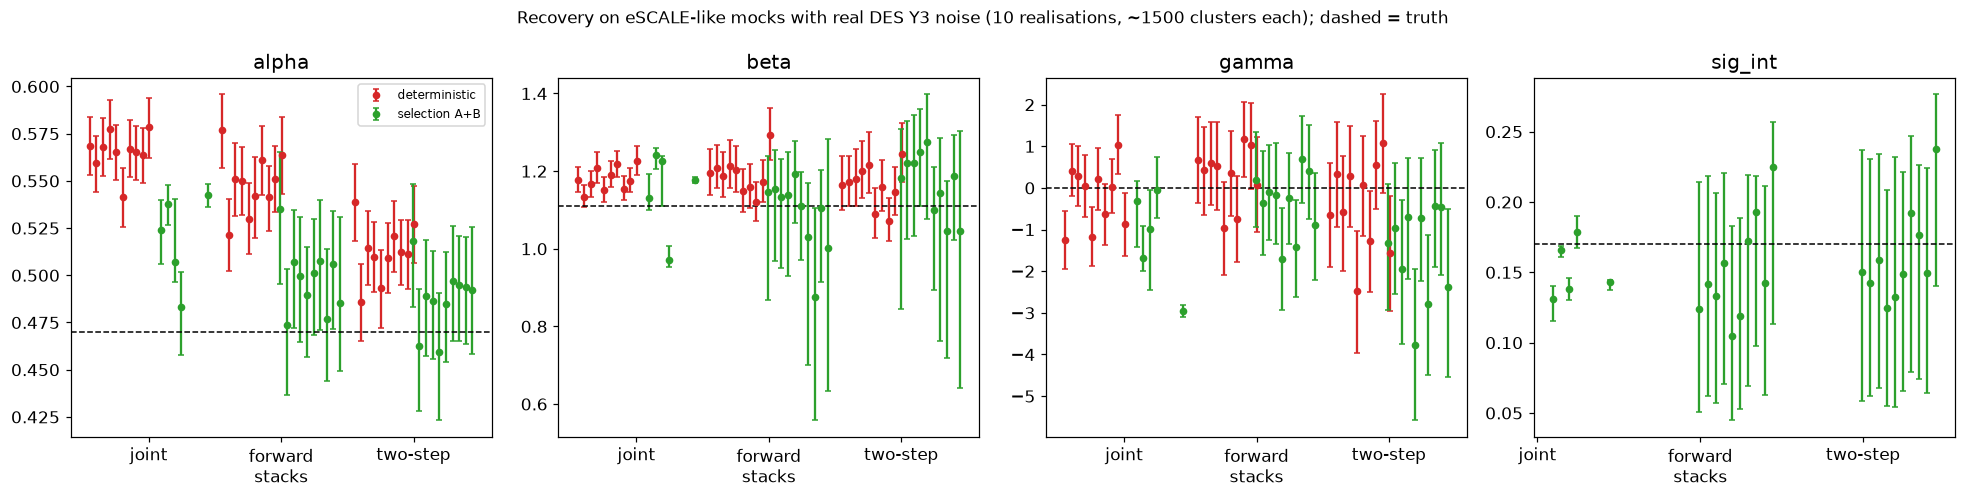

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))
cols = {'det': 'C3', 'A': 'C1', 'AB': 'C2'}
labs = {'det': 'deterministic', 'A': 'selection A (X-ray only)', 'AB': 'selection A+B'}
xpos = {'joint': 0, 'forward': 1, 'twostep': 2}
off = {'det': -0.22, 'A': 0.0, 'AB': 0.22}
for a, p in zip(ax, ['alpha', 'beta', 'gamma', 'sig_int']):
    seen = set()
    for fw, s, sd, r in rows:
        if p not in r: continue
        x = xpos[fw] + off[s] + 0.05 * (sd - np.mean(seeds))
        a.errorbar(x, r[p][1], yerr=[[r[p][1] - r[p][0]], [r[p][2] - r[p][1]]], fmt='o', color=cols[s], ms=4, capsize=2,
                   label=labs[s] if s not in seen else None); seen.add(s)
    a.axhline(TRUTH[p], color='k', ls='--', lw=1)
    a.set_xticks([0, 1, 2]); a.set_xticklabels(['joint', 'forward\nstacks', 'two-step']); a.set_title(p)
ax[0].legend(fontsize=8)
fig.suptitle(f'Recovery on eSCALE-like mocks with real DES Y3 noise ({len(seeds)} realisations, ~1500 clusters each); dashed = truth', fontsize=11)
plt.tight_layout(); plt.show()

## 2 — Real data

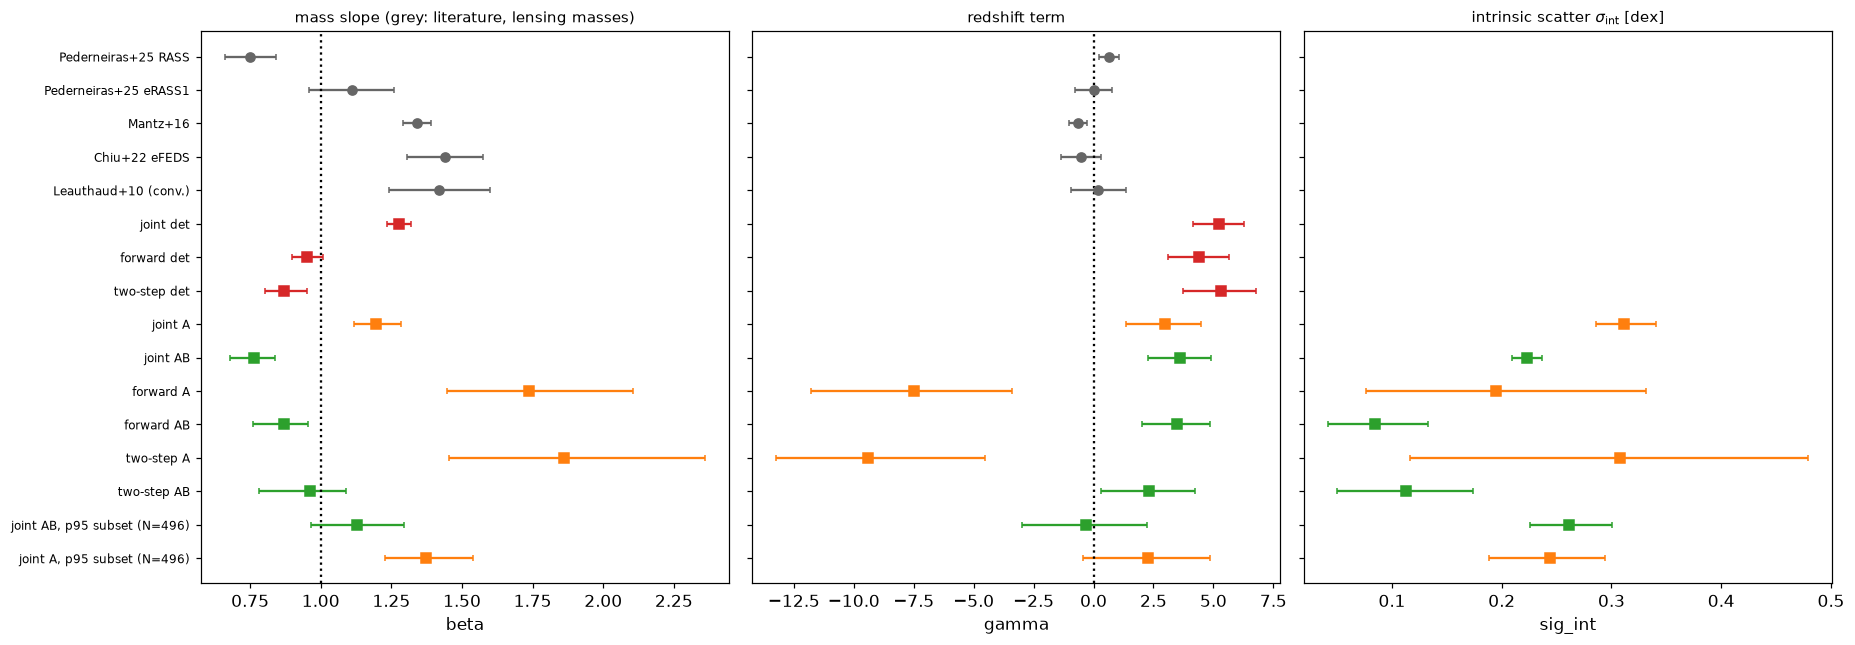

In [4]:
lit = [('Pederneiras+25 RASS', 0.75, 0.09, 0.65, 0.43), ('Pederneiras+25 eRASS1', 1.11, 0.15, 0.00, 0.79),
       ('Mantz+16', 1.34, 0.05, -0.65, 0.38), ('Chiu+22 eFEDS', 1.44, 0.135, -0.51, 0.84), ('Leauthaud+10 (conv.)', 1.42, 0.18, 0.20, 1.14)]
keys = list(real.keys())
fig, ax = plt.subplots(1, 3, figsize=(17, 6), sharey=True)
y = np.arange(len(lit) + len(keys))[::-1]
for a, p in zip(ax, ['beta', 'gamma', 'sig_int']):
    for k, l in enumerate(lit):
        if p == 'beta': a.errorbar(l[1], y[k], xerr=l[2], fmt='o', color='0.4', capsize=2)
        if p == 'gamma': a.errorbar(l[3], y[k], xerr=l[4], fmt='o', color='0.4', capsize=2)
    for k, key in enumerate(keys):
        r = real[key]
        if p not in r: continue
        c = 'C3' if 'det' in key else ('C1' if key.endswith(' A') or 'A,' in key and 'AB' not in key else 'C2')
        a.errorbar(r[p][1], y[len(lit) + k], xerr=[[r[p][1] - r[p][0]], [r[p][2] - r[p][1]]], fmt='s', color=c, capsize=2)
    a.set_xlabel(p)
ax[0].axvline(1, color='k', ls=':'); ax[1].axvline(0, color='k', ls=':')
ax[0].set_yticks(y); ax[0].set_yticklabels([l[0] for l in lit] + keys, fontsize=8)
ax[0].set_title('mass slope (grey: literature, lensing masses)', fontsize=10); ax[1].set_title('redshift term', fontsize=10)
ax[2].set_title(r'intrinsic scatter $\sigma_{\rm int}$ [dex]', fontsize=10)
plt.tight_layout(); plt.show()

## 3 — Reading the results

### Mocks

The mocks have 10 realisations for each framework and model. The joint fit with A+B has only 5: the other five were still sampling after 36 h on Hypatia. Each entry is the mean over realisations ± the error of that mean; the truth is α 0.47, β 1.11, γ 0, σ_int 0.17, f_mis 0.30.

| Framework | Model | α | β | γ | σ_int | f_mis |
|---|---|---|---|---|---|---|
| joint | deterministic | 0.565 ± 0.003 | 1.180 ± 0.010 | −0.19 ± 0.24 | — | 0.48 ± 0.01 |
| joint | A+B (5 seeds) | 0.519 ± 0.011 | 1.15 ± 0.05 | −1.2 ± 0.5 | 0.151 ± 0.009 | 0.47 ± 0.02 |
| forward stacks | deterministic | 0.549 ± 0.005 | 1.190 ± 0.015 | +0.31 ± 0.22 | — | 0.30 ± 0.02 |
| forward stacks | A+B | 0.498 ± 0.006 | 1.089 ± 0.030 | −0.36 ± 0.24 | 0.151 ± 0.012 | 0.31 ± 0.02 |
| two-step | deterministic | 0.512 ± 0.005 | 1.164 ± 0.017 | −0.42 ± 0.35 | — | — |
| two-step | A+B | 0.488 ± 0.005 | 1.167 ± 0.026 | −1.55 ± 0.36 | 0.161 ± 0.010 | — |

* **Deterministic fits** are biased in normalisation (α +0.04 to +0.10) and slope (β +0.05 to +0.08) in every framework. **They do not produce a large γ**: all three are consistent with zero. On these mocks, scatter and the modelled selection do not generate the γ ≈ 4–5 of the real data. The back-of-envelope estimate (γ ≈ +1 from measurement scatter growing with redshift) overpredicts what the full mock shows.
* **Forward-modelled stacks with A+B** recover β, γ, σ_int and f_mis within about 1.5σ of the mean. A residual α offset of +0.028 remains. A likely cause is the bin-centre model evaluation: paper 1.1 found a −0.018 dex mass offset from it, which is about +0.02 in α. This is the framework that currently works.
* **Two-step with A+B** recovers α and σ_int, but γ comes out −1.6 ± 0.4. Comparing the predicted mean stack mass with a single-halo stack fit is too crude for the redshift term.
* **Joint fit with A+B is not yet reliable.**
  * Half the realisations did not converge in 36 h.
  * The converged ones have posteriors 3–4× narrower than their scatter between realisations (β: posterior 0.03, scatter 0.11).
  * Its f_mis is biased high, with or without selection modelling (0.47–0.48 vs 0.30).

  The likely cause is a likelihood made jagged by the discrete mass grid when the per-cluster prior is narrower than the grid spacing. It needs a finer or adaptive grid before its numbers can be used.
* **Option A alone** (X-ray stage only) is not usable for eSCALE. On real data its prior piles up at the bottom of the mass grid, as the mocks predicted.

### Real data

* **Forward stacks, A+B:** β = 0.87 +0.09/−0.11, γ = +3.5 ± 1.4, σ_int = 0.08 ± 0.05. Two-step A+B gives β = 0.96, γ = +2.3 ± 1.9. Selection modelling lowers γ from about 4.4–5.3, but γ stays above zero at about 2.5σ.
* Since the mocks show that scatter and the modelled selection do not produce such a γ, something not in the mock is driving it. The candidates:
  * contamination by wrong optical counterparts or redshifts (the WaZP-match and purity-flag results);
  * an optical selection different from the assumed one;
  * flux errors that behave differently from the mock's.
* **Contamination test.** On the 496 p95 clusters, the joint A+B fit gives β = 1.13 ± 0.17 and γ = −0.3 ± 2.6. That agrees with Pederneiras+25 eRASS1 (1.11, 0.0), whereas the full-sample joint A+B fit gives β = 0.77, γ = 3.6. The joint A+B fit isn't validated yet and the p95 errors are large, so this is suggestive only. It is the clearest lead, and it should be repeated with forward stacks built from the p95 subset.